# 04 · Değerlendirme: PR-AUC, Kalibrasyon, Karar Eğrisi, Bootstrap

**Görseldeki 3. adım:** *Pozitif oranı çok düşük: PR-AUC, kalibrasyon, karar eğrisi analizi.*
**Dikkat notu:** *Çok nadir pozitif (~%6): bootstrap güven aralığı şart.*

03'te modelleri **sıralama** başarısına göre karşılaştırdık. Klinikte kullanılacak bir risk modelinden ise üç şey daha bekleriz:

| Soru | Yöntem |
|---|---|
| En riskli dediği hastalarda gerçekten pozitif var mı? | PR eğrisi, en riskli %k'lık grupta isabet |
| "%20 risk" dediğinde gerçekten %20 mi? | **Kalibrasyon** (eğri, O/E, kesişim, eğim) |
| Bu modelle biyopsi kararı vermek fayda sağlar mı? | **Karar eğrisi analizi** (net fayda) |
| Sonuçlar ne kadar kesin? | **Bootstrap** %95 güven aralıkları |

### Değerlendirilen modeller

| Kod | Model | Neden |
|---|---|---|
| **RF·C** | RF + medyan + grup göstergesi | 03'teki en iyi model (ana model) |
| **RF·A** | RF + medyan, göstergesiz | Göstergenin etkisini görmek için referans |
| **LR·C** | Lojistik regresyon + grup göstergesi | Yorumlanabilir karşılaştırma |
| **RF·C+Platt** | RF·C + Platt (sigmoid) kalibrasyonu | Kalibrasyon düzeltmesi gerekiyor mu? |

In [1]:
import sys
sys.path.append("..")
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, precision_recall_curve, roc_curve

from src.utils import (load_raw, clean, build_pipeline, oof_predictions, calibration_stats,
                       net_benefit, bootstrap, wilson_ci, duplicate_groups, FEATURES, TARGET)

pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", font_scale=0.9)
FIG = Path("../results/figures")
TAB = Path("../results/tables")
SEKIL = Path("../report/sekiller")   # ara rapora girecek dört klinik grafik
SEKIL.mkdir(parents=True, exist_ok=True)

def kaydet(ad, rapor=False):
    """Grafiği results/figures altına, rapor=True ise report/sekiller altına da kaydeder."""
    plt.savefig(FIG / ad, dpi=150)
    if rapor:
        plt.savefig(SEKIL / ad, dpi=300)

df = clean(load_raw())
X = df[FEATURES]
y = df[TARGET].to_numpy()
prev = y.mean()
print(f"{len(y)} hasta, {y.sum()} biyopsi+ (%{prev*100:.1f})")

858 hasta, 55 biyopsi+ (%6.4)


## 1. Dışarıda bırakılmış (out-of-fold) tahminler

Kalibrasyon ve karar eğrisi için **her hastanın** bir risk tahminine ihtiyacımız var ve bu tahmin, o hastayı **eğitimde hiç görmemiş** bir modelden gelmeli. Bunu şöyle sağlıyoruz:

1. Veriyi 5 kata böl. Her katı, diğer 4 katla eğitilen modelle tahmin et. Böylece her hasta tam bir kez "test" hastası olur.
2. Bunu farklı bölmelerle **10 kez** tekrarla.
3. Her hasta için 10 tahminin **ortalamasını** al. Grafikler ve bootstrap bu ortalama tahminle yapılır. Tekrar bazındaki metrikler de ayrıca raporlanır.

⏱️ Bu hücre yaklaşık 3–4 dakika sürer (Platt kalibrasyonu iç içe CV gerektirdiği için en yavaşı).

In [2]:
rf = lambda: RandomForestClassifier(n_estimators=500, min_samples_leaf=5, n_jobs=-1, random_state=0)
MODELS = {
    "RF·C":       build_pipeline(rf(), group=True),
    "RF·A":       build_pipeline(rf()),
    "LR·C":       build_pipeline(LogisticRegression(max_iter=2000), group=True),
    "RF·C+Platt": CalibratedClassifierCV(build_pipeline(rf(), group=True), method="sigmoid", cv=5),
}

OOF = {}
for name, model in MODELS.items():
    OOF[name] = oof_predictions(model, X, y, n_repeats=10)   # (10 tekrar, 858 hasta)
    print(f"✓ {name}")

P = {name: m.mean(axis=0) for name, m in OOF.items()}       # hasta başına ortalama tahmin

✓ RF·C


✓ RF·A


✓ LR·C


✓ RF·C+Platt


## 2. Ayırt edicilik: PR-AUC ve ROC-AUC

In [3]:
rows = []
for name, M in OOF.items():
    rows.append({"model": name,
                 "PR-AUC (tekrar ort.)": np.mean([average_precision_score(y, r) for r in M]),
                 "ROC-AUC (tekrar ort.)": np.mean([roc_auc_score(y, r) for r in M]),
                 "Brier (tekrar ort.)": np.mean([brier_score_loss(y, r) for r in M])})
rows.append({"model": "herkese %6.4", "PR-AUC (tekrar ort.)": prev, "ROC-AUC (tekrar ort.)": 0.5,
             "Brier (tekrar ort.)": prev * (1 - prev)})
pd.DataFrame(rows).set_index("model").round(4)

,PR-AUC (tekrar ort.),ROC-AUC (tekrar ort.),Brier (tekrar ort.)
model,,,
RF·C,0.1560,0.6943,0.0577
RF·A,0.1534,0.6729,0.0579
LR·C,0.1360,0.6323,0.0609
RF·C+Platt,0.1510,0.6857,0.0581
herkese %6.4,0.0641,0.5000,0.0600


> **03 ile neden farklı?** 03'te PR-AUC her test katında (≈171 hasta, ≈11 pozitif) ayrı hesaplanıp ortalandı (≈0.19). Burada 5 katın tahminleri birleştirilip **858 hastanın tamamında** tek bir PR-AUC hesaplanıyor (≈0.16). Küçük katlarda PR-AUC hem daha oynak hem de yukarı yönlü yanlı olabiliyor; ayrıca birleştirince farklı katlardaki modellerin olasılık ölçeklerinin uyumu da sınanmış oluyor. İki sayı da doğru ama farklı şeyleri ölçüyor. Raporda **birleştirilmiş** değeri (bu notebook) asıl sonuç olarak vermek daha temkinli.

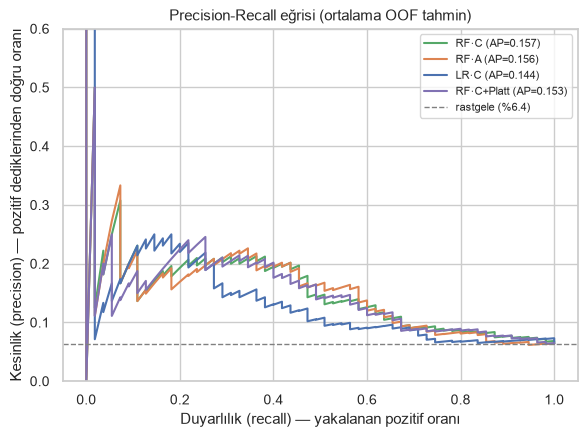

In [4]:
fig, ax = plt.subplots(figsize=(6, 4.5))
colors = {"RF·C": sns.color_palette()[2], "RF·A": sns.color_palette()[1],
          "LR·C": sns.color_palette()[0], "RF·C+Platt": sns.color_palette()[4]}
for name, p in P.items():
    pr, rc, _ = precision_recall_curve(y, p)
    ax.plot(rc, pr, label=f"{name} (AP={average_precision_score(y, p):.3f})", color=colors[name], lw=1.5)
ax.axhline(prev, ls="--", color="grey", lw=1, label=f"rastgele (%{prev*100:.1f})")
ax.set_xlabel("Duyarlılık (recall) — yakalanan pozitif oranı")
ax.set_ylabel("Kesinlik (precision) — pozitif dediklerinden doğru oranı")
ax.set_title("Precision-Recall eğrisi (ortalama OOF tahmin)")
ax.set_ylim(0, 0.6)
ax.legend(fontsize=8)
plt.tight_layout()
kaydet("04_pr_egrisi.png", rapor=True)
plt.show()

### ROC eğrisi

ROC eğrisi, her eşikte **duyarlılığı** (yakalanan pozitif oranı) **1 − özgüllüğe** (yanlış alarm oranı) karşı çizer. Pozitif oranından bağımsızdır; bu yüzden %6.4 gibi nadir bir hedefte iyimser görünebilir ve PR eğrisiyle **birlikte** okunmalıdır. Köşegen, rastgele sıralamayı (AUC = 0.5) gösterir.

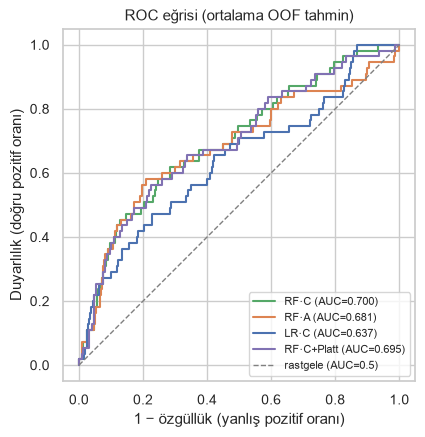

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for name, p in P.items():
    fpr, tpr, _ = roc_curve(y, p)
    ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y, p):.3f})", color=colors[name], lw=1.5)
ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=1, label="rastgele (AUC=0.5)")
ax.set_xlabel("1 − özgüllük (yanlış pozitif oranı)")
ax.set_ylabel("Duyarlılık (doğru pozitif oranı)")
ax.set_title("ROC eğrisi (ortalama OOF tahmin)")
ax.set_aspect("equal")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
kaydet("04_roc_egrisi.png", rapor=True)
plt.show()

### En riskli hastalar ne kadar isabetli?

PR eğrisini daha somut okumak için: model hastaları riske göre sıralasın, **en riskli %5 / %10 / %20**'yi seçsin. Bu grupta kaç pozitif var?

In [6]:
rows = []
for frac in [0.05, 0.10, 0.20]:
    k = int(round(frac * len(y)))
    for name in ["RF·C", "RF·A", "LR·C"]:
        top = np.argsort(-P[name])[:k]
        tp = int(y[top].sum())
        lo, hi = wilson_ci(tp, k)
        rows.append({"en riskli": f"%{frac*100:.0f} ({k} hasta)", "model": name,
                     "pozitif": f"{tp}/{k}", "kesinlik %": round(tp / k * 100, 1),
                     "GA %": f"{lo*100:.0f}–{hi*100:.0f}",
                     "yakalanan pozitif %": round(tp / y.sum() * 100, 1),
                     "lift (×rastgele)": round(tp / k / prev, 1)})
topk = pd.DataFrame(rows)
topk

,en riskli,model,pozitif,kesinlik %,GA %,yakalanan pozitif %,lift (×rastgele)
0,%5 (43 hasta),RF·C,6/43,14.0,7–27,10.9,2.2
1,%5 (43 hasta),RF·A,6/43,14.0,7–27,10.9,2.2
2,%5 (43 hasta),LR·C,10/43,23.3,13–38,18.2,3.6
3,%10 (86 hasta),RF·C,18/86,20.9,14–31,32.7,3.3
4,%10 (86 hasta),RF·A,19/86,22.1,15–32,34.5,3.4
5,%10 (86 hasta),LR·C,15/86,17.4,11–27,27.3,2.7
6,%20 (172 hasta),RF·C,26/172,15.1,11–21,47.3,2.4
7,%20 (172 hasta),RF·A,28/172,16.3,12–23,50.9,2.5
8,%20 (172 hasta),LR·C,23/172,13.4,9–19,41.8,2.1


**Okuma örneği:** RF·C'nin en riskli bulduğu %10'luk grupta (86 hasta) pozitif oranı genel orandan yaklaşık **3 kat** yüksek. Ama bu grup yine de pozitiflerin yalnızca üçte birini içeriyor; pozitiflerin çoğu "düşük riskli" görünen hastaların arasında. Bu model **tarama testinin yerine geçemez**, en fazla risk sıralamasına katkı sağlayabilir.

## 3. Kalibrasyon: model "%X risk" dediğinde gerçekten %X mi?

Kalibrasyon, ayırt edicilikten **ayrı** bir özellik. Mükemmel sıralama yapan bir model, olasılıkları sistematik olarak abartabilir. Klinik risk modelinde bu tehlikelidir: "%30 risk" duyan hekim ve hasta farklı karar verir.

| Ölçü | İdeal | Anlamı |
|---|---|---|
| **O/E** (gözlenen / beklenen) | 1 | <1: model riski abartıyor, >1: hafife alıyor |
| **Kesişim** (calibration-in-the-large) | 0 | Ortalama düzeyde sistematik kayma |
| **Eğim** | 1 | <1: tahminler fazla uç (aşırı güvenli, genelde aşırı öğrenme), >1: fazla ılımlı |
| **Brier** | düşük | Olasılık hatası; ayırt edicilik + kalibrasyon birlikte |

In [7]:
cal = pd.DataFrame({name: calibration_stats(y, p) for name, p in P.items()}).T
cal["Brier"] = [brier_score_loss(y, p) for p in P.values()]
cal["en yüksek tahmin"] = [p.max() for p in P.values()]
cal.to_csv(TAB / "04_kalibrasyon.csv", encoding="utf-8-sig")
cal.round(3)

,ort_tahmin,gözlenen,O/E,kesişim,eğim,Brier,en yüksek tahmin
RF·C,0.064,0.064,1.000,0.000,0.916,0.057,0.298
RF·A,0.064,0.064,1.000,-0.000,0.870,0.058,0.296
LR·C,0.066,0.064,0.968,-0.038,0.634,0.060,0.636
RF·C+Platt,0.063,0.064,1.019,0.020,1.214,0.058,0.303


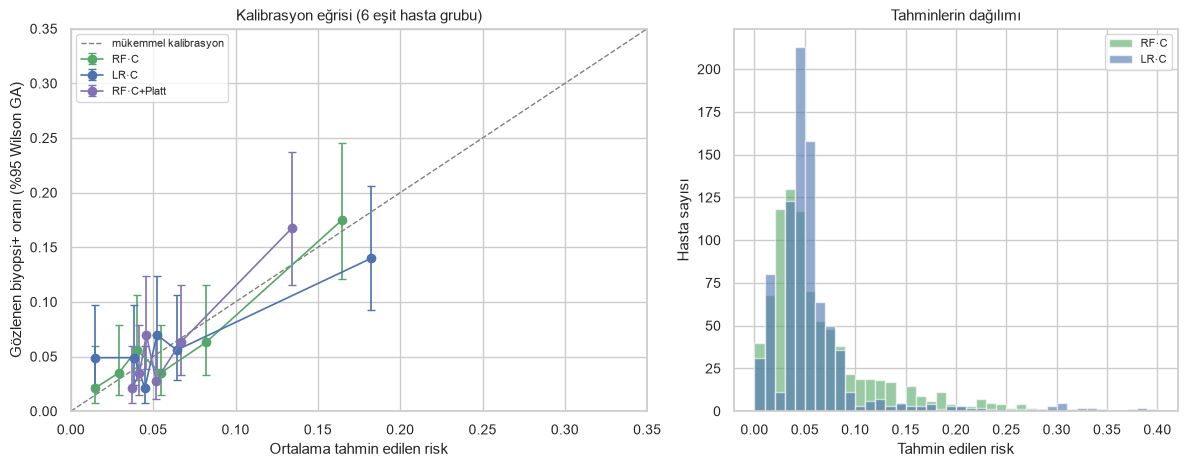

In [8]:
def reliability(ax, p, color, label, n_bins=6):
    # Eşit sayıda hasta içeren (kantil) gruplar: pozitif az olduğu için eşit genişlikli gruplar boş kalırdı
    bins = pd.qcut(p, n_bins, duplicates="drop")
    g = pd.DataFrame({"p": p, "y": y}).groupby(bins, observed=True).agg(p=("p", "mean"), k=("y", "sum"), n=("y", "size"))
    ci = np.array([wilson_ci(k, n) for k, n in zip(g["k"], g["n"])])
    obs = g["k"] / g["n"]
    ax.errorbar(g["p"], obs, yerr=[obs - ci[:, 0], ci[:, 1] - obs], fmt="o-", color=color, capsize=3, label=label, lw=1.2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
for name in ["RF·C", "LR·C", "RF·C+Platt"]:
    reliability(ax, P[name], colors[name], name)
ax.plot([0, 0.35], [0, 0.35], ls="--", color="grey", lw=1, label="mükemmel kalibrasyon")
ax.set_xlim(0, 0.35); ax.set_ylim(0, 0.35)
ax.set_xlabel("Ortalama tahmin edilen risk")
ax.set_ylabel("Gözlenen biyopsi+ oranı (%95 Wilson GA)")
ax.set_title("Kalibrasyon eğrisi (6 eşit hasta grubu)")
ax.legend(fontsize=8)

ax = axes[1]
for name in ["RF·C", "LR·C"]:
    ax.hist(P[name], bins=40, range=(0, 0.4), alpha=0.6, color=colors[name], label=name)
ax.set_xlabel("Tahmin edilen risk")
ax.set_ylabel("Hasta sayısı")
ax.set_title("Tahminlerin dağılımı")
ax.legend(fontsize=8)
plt.tight_layout()
kaydet("04_kalibrasyon.png", rapor=True)
plt.show()

**Yorum:**
- **RF·C iyi kalibre:** Ortalama tahmin, gözlenen oranla aynı (O/E ≈ 1.0) ve eğim 1'e yakın (≈0.9). Model riskleri sistematik olarak abartmıyor ya da küçümsemiyor. Tahminleri dar bir aralıkta (en fazla ≈%30): model "bu hastanın riski kesin çok yüksek" demiyor. Bu, zayıf sinyalle uyumlu ve **dürüst** bir davranış.
- **LR·C aşırı güvenli:** Eğim ≈0.6. Bazı hastalara %60'a varan riskler veriyor ama bu yüksek tahminler gerçekleşmiyor. Bu, aşırı öğrenmenin tipik işareti. Daha güçlü düzenlileştirme (küçük `C`) bunu azaltabilir.
- **Platt kalibrasyonu gerekli değil:** RF·C zaten kalibre. Platt uygulanınca eğim 1'in üzerine çıkıyor (tahminler fazla ılımlılaşıyor) ve PR-AUC biraz düşüyor. 55 pozitifle ek bir kalibrasyon modeli öğrenmek, düzelttiğinden fazla gürültü ekliyor.

## 4. Karar eğrisi analizi: model klinikte fayda sağlar mı?

**Senaryo:** Hekim "riski **pt**'den büyük olana biyopsi yap" kuralını kullansın. **pt** eşiği, hekimin bir kanseri kaçırmayı gereksiz bir biyopsiye göre ne kadar ağır gördüğünü yansıtır. Örneğin pt = %10 şu anlama gelir: "1 gerçek pozitifi yakalamak için 9 gereksiz biyopsiyi kabul ederim."

**Net fayda** (Vickers & Elkin, 2006):
$$\text{Net fayda} = \frac{TP}{n} - \frac{FP}{n} \times \frac{p_t}{1-p_t}$$

Model, iki basit stratejiyle karşılaştırılır:
- **Herkese biyopsi:** Tüm pozitifler yakalanır ama çok sayıda gereksiz biyopsi yapılır.
- **Kimseye biyopsi yapma:** Net fayda = 0.

Bir model, ancak makul eşik aralığında **ikisinden de yüksek** net fayda verirse klinik olarak işe yarar.

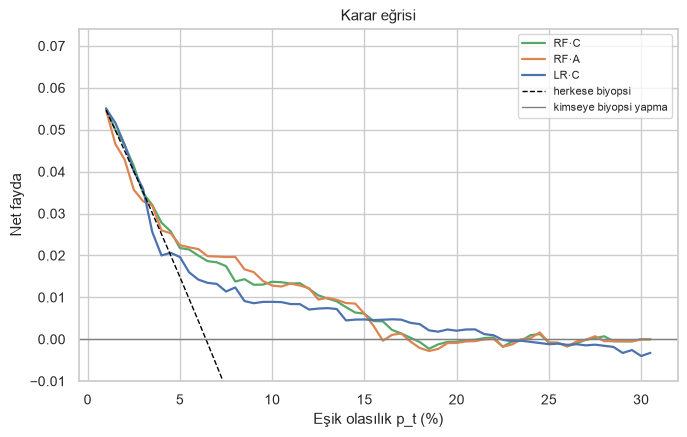

In [9]:
th = np.round(np.arange(0.01, 0.31, 0.005), 3)
nb = {name: net_benefit(y, P[name], th)[0] for name in ["RF·C", "RF·A", "LR·C"]}
nb_all = net_benefit(y, P["RF·C"], th)[1]

fig, ax = plt.subplots(figsize=(7, 4.5))
for name, v in nb.items():
    ax.plot(th * 100, v, label=name, color=colors[name], lw=1.6)
ax.plot(th * 100, nb_all, label="herkese biyopsi", color="black", lw=1, ls="--")
ax.axhline(0, color="grey", lw=1, label="kimseye biyopsi yapma")
ax.set_ylim(-0.01, prev + 0.01)
ax.set_xlabel("Eşik olasılık p_t (%)")
ax.set_ylabel("Net fayda")
ax.set_title("Karar eğrisi")
ax.legend(fontsize=8)
plt.tight_layout()
kaydet("04_karar_egrisi.png", rapor=True)
plt.show()

In [10]:
rows = []
for t in [0.03, 0.05, 0.10, 0.15, 0.20]:
    i = int(np.argmin(np.abs(th - t)))
    best_default = max(nb_all[i], 0)
    row = {"eşik": f"%{t*100:.0f}", "herkese biyopsi": nb_all[i], "kimseye": 0.0}
    for name in nb:
        row[name] = nb[name][i]
    row["RF·C − en iyi basit strateji (100 hastada)"] = (nb["RF·C"][i] - best_default) * 100
    pos = P["RF·C"] >= t
    row["RF·C: biyopsi önerilen"] = int(pos.sum())
    row["RF·C: yakalanan +"] = f"{int(y[pos].sum())}/{int(y.sum())}"
    rows.append(row)
dca = pd.DataFrame(rows).set_index("eşik")
dca.to_csv(TAB / "04_karar_egrisi.csv", encoding="utf-8-sig")
dca.round(4)

,herkese biyopsi,kimseye,RF·C,RF·A,LR·C,RF·C − en iyi basit strateji (100 hastada),RF·C: biyopsi önerilen,RF·C: yakalanan +
eşik,,,,,,,,
%3,0.0352,0.0,0.0349,0.0330,0.0360,-0.0264,632,48/55
%5,0.0148,0.0,0.0218,0.0225,0.0196,0.6932,385,37/55
%10,-0.0399,0.0,0.0137,0.0128,0.0089,1.3727,154,26/55
%15,-0.1011,0.0,0.0061,0.0061,0.0047,0.6102,77,16/55
%20,-0.1699,0.0,-0.0006,-0.0009,0.0020,-0.0583,32,6/55


**Yorum:**
- **Çok düşük eşiklerde (≈%3–4 altı)** "herkese biyopsi" en iyi strateji. Hekim bir pozitifi kaçırmamak için çok sayıda gereksiz biyopsiyi kabul ediyorsa model gereksiz.
- **Yaklaşık %5–15 aralığında** RF·C her iki basit stratejiden de daha iyi. Ama fark küçük: tablodaki "100 hastada" sütunu, en iyi basit stratejiye göre 100 hasta başına **≈0.6–1.4 ek net doğru pozitif** gösteriyor.
- **Yüksek eşiklerde (≈%20 üstü)** model neredeyse hiç hastaya biyopsi önermiyor ve fayda sıfıra iniyor.
- **Önemli:** Model pozitiflerin önemli bir kısmını **kaçırıyor**. %5 eşiğinde 55 pozitifin 18'i, %10 eşiğinde ise yarısından fazlası (29'u) biyopsi önerilmeyen hastalar arasında kalıyor. Biyopsi düşük riskli bir işlem, kanseri kaçırmanın bedeli ise çok yüksek. Bu yüzden gerçek klinikte bu model biyopsi kararını **tek başına** veremez. En fazla tarama sonuçlarına ek bir bilgi olabilir.

## 5. Bootstrap güven aralıkları

55 pozitifle her metrik büyük belirsizlik taşıyor. Hastaları **yerine koyarak** 2000 kez yeniden örnekleyip her örneklemde metrikleri yeniden hesaplıyoruz. Dağılımın %2.5 ve %97.5'lik dilimleri **%95 güven aralığını** verir.

Tüm modeller **aynı** bootstrap örneklemlerinde değerlendirildiği için **farkların** güven aralığı da hesaplanabilir (eşleştirilmiş bootstrap).

> **Kapsam notu:** Bu aralıklar *test hastalarının örneklem değişkenliğini* yansıtır. Modelin farklı bir eğitim kümesiyle nasıl değişeceğini tam olarak kapsamaz; o belirsizliğin bir kısmı 10 tekrarın ortalaması alınarak zaten yumuşatıldı.

⏱️ Yaklaşık 1–2 dakika.

In [11]:
main = {k: P[k] for k in ["RF·C", "RF·A", "LR·C"]}
B = {
    "PR-AUC":  bootstrap(y, main, average_precision_score, n_boot=2000, seed=1),
    "ROC-AUC": bootstrap(y, main, roc_auc_score, n_boot=2000, seed=1),
    "Brier":   bootstrap(y, main, brier_score_loss, n_boot=2000, seed=1),
    "Kalibrasyon eğimi": bootstrap(y, main, lambda yy, pp: calibration_stats(yy, pp)["eğim"], n_boot=2000, seed=1),
}

point = {"PR-AUC": average_precision_score, "ROC-AUC": roc_auc_score, "Brier": brier_score_loss,
         "Kalibrasyon eğimi": lambda yy, pp: calibration_stats(yy, pp)["eğim"]}
rows = []
for metric, samples in B.items():
    for name in main:
        lo, hi = samples[name].quantile([0.025, 0.975])
        rows.append({"metrik": metric, "model": name, "değer": point[metric](y, main[name]), "GA alt": lo, "GA üst": hi})
boot = pd.DataFrame(rows)
boot.to_csv(TAB / "04_bootstrap_ga.csv", index=False, encoding="utf-8-sig")
boot.pivot(index="model", columns="metrik", values=["değer", "GA alt", "GA üst"]).round(3)

değer                                  GA alt                                  GA üst                                 
metrik  Brier Kalibrasyon eğimi PR-AUC ROC-AUC  Brier Kalibrasyon eğimi PR-AUC ROC-AUC  Brier Kalibrasyon eğimi PR-AUC ROC-AUC
model                                                                                                                         
LR·C    0.060             0.634  0.144   0.637  0.046             0.352  0.087   0.549  0.075             0.921  0.225   0.719
RF·A    0.058             0.870  0.156   0.681  0.044             0.467  0.102   0.591  0.071             1.262  0.249   0.764
RF·C    0.057             0.916  0.157   0.700  0.044             0.564  0.101   0.621  0.071             1.297  0.250   0.773

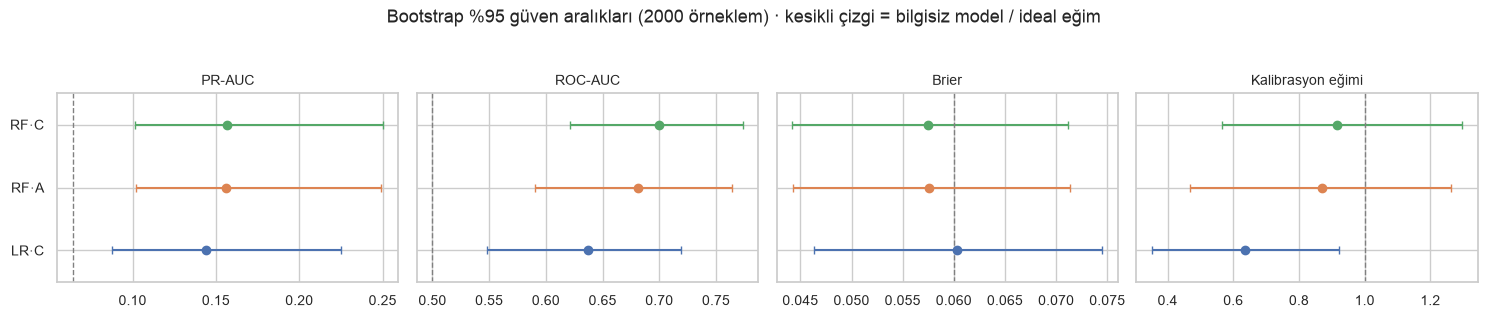

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
refs = {"PR-AUC": prev, "ROC-AUC": 0.5, "Brier": prev * (1 - prev), "Kalibrasyon eğimi": 1.0}
for ax, metric in zip(axes, B):
    sub = boot[boot["metrik"] == metric].reset_index(drop=True)
    for i, r in sub.iterrows():
        ax.errorbar(r["değer"], i, xerr=[[r["değer"] - r["GA alt"]], [r["GA üst"] - r["değer"]]],
                    fmt="o", capsize=3, color=colors[r["model"]])
    ax.axvline(refs[metric], ls="--", color="grey", lw=1)
    ax.set_yticks(range(len(sub)))
    ax.set_yticklabels(sub["model"] if metric == "PR-AUC" else [])
    ax.set_ylim(-0.5, len(sub) - 0.5)
    ax.invert_yaxis()
    ax.set_title(metric, fontsize=10)
plt.suptitle("Bootstrap %95 güven aralıkları (2000 örneklem) · kesikli çizgi = bilgisiz model / ideal eğim", y=1.05)
plt.tight_layout()
plt.savefig(FIG / "04_bootstrap_ga.png", dpi=150, bbox_inches="tight")
plt.show()

### Gösterge gerçekten fark yaratıyor mu? (eşleştirilmiş bootstrap farkı)

In [13]:
rows = []
for metric in ["PR-AUC", "ROC-AUC", "Brier"]:
    for a, b in [("RF·C", "RF·A"), ("RF·C", "LR·C")]:
        d = B[metric][a] - B[metric][b]
        lo, hi = d.quantile([0.025, 0.975])
        better = (d < 0).mean() if metric == "Brier" else (d > 0).mean()
        rows.append({"metrik": metric, "karşılaştırma": f"{a} − {b}", "fark": point[metric](y, P[a]) - point[metric](y, P[b]),
                     "GA alt": lo, "GA üst": hi, "GA 0'ı içeriyor mu": "evet" if lo <= 0 <= hi else "HAYIR",
                     f"{a} daha iyi (% örneklem)": round(better * 100)})
diff = pd.DataFrame(rows)
diff.to_csv(TAB / "04_bootstrap_farklar.csv", index=False, encoding="utf-8-sig")
diff.round(4)

,metrik,karşılaştırma,fark,GA alt,GA üst,GA 0'ı içeriyor mu,RF·C daha iyi (% örneklem)
0,PR-AUC,RF·C − RF·A,0.0006,-0.0069,0.0083,evet,57
1,PR-AUC,RF·C − LR·C,0.0127,-0.0389,0.0756,evet,74
2,ROC-AUC,RF·C − RF·A,0.0189,-0.0067,0.0458,evet,93
3,ROC-AUC,RF·C − LR·C,0.0629,0.0001,0.1263,HAYIR,98
4,Brier,RF·C − RF·A,-0.0001,-0.0004,0.0002,evet,79
5,Brier,RF·C − LR·C,-0.0028,-0.0057,0.0002,evet,97


**Yorum:**
- **Güven aralıkları geniş.** RF·C'nin PR-AUC'u ≈0.10–0.25 arasında herhangi bir değer olabilir. Yine de alt sınır rastgele düzeyin (0.064) belirgin şekilde üzerinde, yani **sinyal gerçek**.
- **Kalibrasyon eğiminin aralığı da çok geniş** (≈0.6–1.3). 55 pozitifle kalibrasyonu kesin olarak ölçmek mümkün değil; nokta tahmini iyi ama belirsizliği yüksek.
- **RF·C − RF·A (göstergenin etkisi):** Üç metriğin hiçbirinde fark anlamlı değil; tüm aralıklar 0'ı içeriyor. ROC-AUC'ta RF·C, bootstrap örneklemlerinin %93'ünde daha iyi. Bu, 03'teki "artırma eğiliminde ama sınırda" sonucuyla tutarlı.
- **RF·C − LR·C:** ROC-AUC'ta RF anlamlı şekilde daha iyi (aralık 0'ın hemen üzerinde). PR-AUC ve Brier'de fark anlamlı değil.

## 6. Eksiklik göstergesi hastaları nasıl etkiliyor?

02'de hormonal kontraseptif (HK) sorusunu cevaplamayan 108 hastanın hiçbirinde biyopsinin pozitif çıkmadığını görmüştük. Göstergeli model (RF·C) bu bilgiyi kullanıyor mu? Bu iki hasta grubuna verilen ortalama risklere bakalım:

In [14]:
hk_missing = df["Hormonal Contraceptives (years)"].isna().to_numpy()
rows = []
for name in ["RF·A", "RF·C", "LR·C"]:
    rows.append({"model": name,
                 "HK cevapsız: ort. risk %": P[name][hk_missing].mean() * 100,
                 "HK cevaplı: ort. risk %": P[name][~hk_missing].mean() * 100,
                 "oran (cevapsız / cevaplı)": P[name][hk_missing].mean() / P[name][~hk_missing].mean()})
rows.append({"model": "gerçek (gözlenen)", "HK cevapsız: ort. risk %": y[hk_missing].mean() * 100,
             "HK cevaplı: ort. risk %": y[~hk_missing].mean() * 100,
             "oran (cevapsız / cevaplı)": y[hk_missing].mean() / y[~hk_missing].mean()})
pd.DataFrame(rows).set_index("model").round(2)

,HK cevapsız: ort. risk %,HK cevaplı: ort. risk %,oran (cevapsız / cevaplı)
model,,,
RF·A,4.46,6.69,0.67
RF·C,2.38,6.99,0.34
LR·C,1.51,7.36,0.20
gerçek (gözlenen),0.00,7.33,0.00


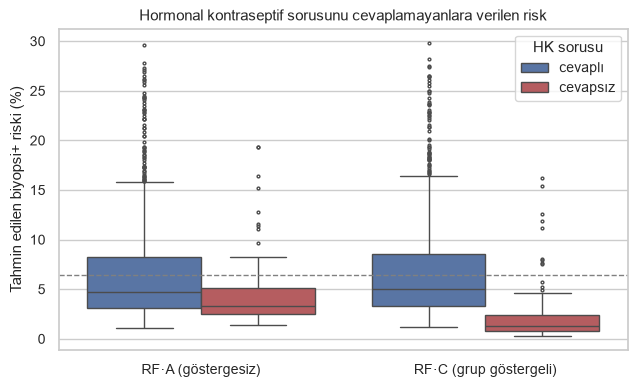

In [15]:
plot = pd.DataFrame({"risk": np.r_[P["RF·A"], P["RF·C"]] * 100,
                     "model": ["RF·A (göstergesiz)"] * len(y) + ["RF·C (grup göstergeli)"] * len(y),
                     "HK sorusu": np.tile(np.where(hk_missing, "cevapsız", "cevaplı"), 2)})
fig, ax = plt.subplots(figsize=(6.5, 4))
sns.boxplot(data=plot, x="model", y="risk", hue="HK sorusu", ax=ax, fliersize=2,
            palette={"cevaplı": sns.color_palette()[0], "cevapsız": sns.color_palette()[3]})
ax.axhline(prev * 100, ls="--", color="grey", lw=1)
ax.set_ylabel("Tahmin edilen biyopsi+ riski (%)")
ax.set_xlabel("")
ax.set_title("Hormonal kontraseptif sorusunu cevaplamayanlara verilen risk")
plt.tight_layout()
plt.savefig(FIG / "04_hk_eksik_risk.png", dpi=150)
plt.show()

**Yorum:** Göstergesiz model (RF·A) de bu hastalara biraz daha düşük risk veriyor (cevaplayanlara verilenin ≈2/3'ü). Bunun nedeni, bu hastaların daha genç olması gibi gözlenen farklar. Gösterge eklenince bu oran **≈1/3'e** iniyor; LR·C'de ise ≈1/5'e kadar düşüyor. Yani modeller, "soruyu cevaplamamış olmayı" ayrı bir düşük risk işareti olarak kullanıyor.

Bu, modelin 02'deki bulguyu **öğrendiğini** gösteriyor. Ama klinik ve etik açıdan kritik bir soru doğuruyor: **"Soruyu cevaplamadı → riski düşük" kuralına güvenmeli miyiz?**
- Bu ilişki bu veri setinin toplanma biçimine özgü olabilir (hangi hastalar, hangi koşullarda cevaplamadı?).
- Başka bir hastanede, mahrem soruları cevaplamayanlar tam tersine yüksek riskli olabilir (MNAR senaryosu).
- Model bu kısayolu kullanırsa, cevap vermemeyi seçen bir hastanın riski sistematik olarak küçümsenebilir.

Bunu 05'te SHAP ile ayrıntılı inceleyip etik tartışmaya bağlayacağız.

## 7. Bölme stratejisi: hasta kimliği yok, tekrar eden kayıtlar var

**Neden GroupKFold değil, katmanlı KFold?** Bu veri setinde her satır bir hastanın tek ziyaretidir ve **hasta kimliği sütunu yoktur**. Dolayısıyla "aynı hastanın satırları aynı katta kalsın" diyebileceğimiz bir grup sütunu da yoktur. Bu yüzden ana analizde **katmanlı 5 kat × 10 tekrar** kullanıldı (pozitif oranı %6.4 olduğu için her katta yaklaşık 11 pozitif kalması için katmanlama şart).

**Ama bir risk var:** 01'de **birebir aynı 23 satır** bulduk (20 grup, toplam 43 satır). Bunlar aynı hastanın yanlışlıkla iki kez girilmiş kaydı olabilir. Öyleyse klasik bölmede bir kopya eğitimde, diğeri testte olur ve model test hastasını **önceden görmüş** olur. Bu, bir tür sızıntıdır.

**Duyarlılık analizi:** Tekrar eden satırlara ortak bir grup numarası verip (`duplicate_groups`) **StratifiedGroupKFold** ile aynı analizi tekrarlıyoruz. Sonuç değişmiyorsa ana bölme stratejisi güvenilirdir.

> **Sınırlılık:** Hasta kimliği olmadığı için *birebir aynı olmayan* ama aynı hastaya ait kayıtları tespit edemeyiz. Bu, raporun sınırlılıklar bölümüne girer.

In [16]:
groups = duplicate_groups(load_raw())          # ham veride birebir aynı satırlar → aynı grup
sizes = pd.Series(groups).value_counts()
multi = sizes[sizes > 1].index
print(f"{len(sizes)} grup; {len(multi)} grupta birden çok satır ({sizes[multi].sum()} satır)")
print("Tekrar eden gruplarda biyopsi+ olan grup sayısı:", int(pd.Series(y).groupby(groups).sum()[multi].gt(0).sum()))

# Klasik katmanlı bölmede bu grupların kaçı eğitim ve test arasında bölünüyor?
from sklearn.model_selection import StratifiedKFold
split = []
for r in range(10):
    fold = np.empty(len(y), dtype=int)
    for k, (_, te) in enumerate(StratifiedKFold(5, shuffle=True, random_state=42 + r).split(X, y)):
        fold[te] = k
    split.append(sum(len(set(fold[groups == g])) > 1 for g in multi))
print(f"StratifiedKFold: {len(multi)} tekrar grubunun her tekrarda ortalama {np.mean(split):.1f} tanesi eğitim/test arasında bölünüyor")

835 grup; 20 grupta birden çok satır (43 satır)
Tekrar eden gruplarda biyopsi+ olan grup sayısı: 1
StratifiedKFold: 20 tekrar grubunun her tekrarda ortalama 16.4 tanesi eğitim/test arasında bölünüyor


In [17]:
# StratifiedKFold sonuçları 1. bölümde hesaplandı (OOF); aynı modelleri grup bazlı bölmeyle tekrar çalıştırıyoruz
OOF_G = {name: oof_predictions(MODELS[name], X, y, n_repeats=10, groups=groups) for name in ["RF·C", "LR·C"]}

rows = []
for name in ["RF·C", "LR·C"]:
    for bolme, M in [("StratifiedKFold", OOF[name]), ("StratifiedGroupKFold", OOF_G[name])]:
        pr = [average_precision_score(y, r) for r in M]
        roc = [roc_auc_score(y, r) for r in M]
        cal_s = calibration_stats(y, M.mean(axis=0))
        rows.append({"model": name, "bölme": bolme,
                     "PR-AUC (ort ± ss)": f"{np.mean(pr):.3f} ± {np.std(pr):.3f}",
                     "ROC-AUC (ort ± ss)": f"{np.mean(roc):.3f} ± {np.std(roc):.3f}",
                     "Brier": round(np.mean([brier_score_loss(y, r) for r in M]), 4),
                     "O/E": round(cal_s["O/E"], 2), "kalibrasyon eğimi": round(cal_s["eğim"], 2)})
bolme_tab = pd.DataFrame(rows).set_index(["model", "bölme"])
bolme_tab.to_csv(TAB / "04_bolme_duyarlilik.csv", encoding="utf-8-sig")
bolme_tab

PR-AUC (ort ± ss) ROC-AUC (ort ± ss)   Brier   O/E  kalibrasyon eğimi
model bölme                                                                                     
RF·C  StratifiedKFold          0.156 ± 0.015      0.694 ± 0.016  0.0577  1.00               0.92
      StratifiedGroupKFold     0.149 ± 0.014      0.686 ± 0.013  0.0582  1.01               0.86
LR·C  StratifiedKFold          0.136 ± 0.010      0.632 ± 0.015  0.0609  0.97               0.63
      StratifiedGroupKFold     0.131 ± 0.012      0.628 ± 0.025  0.0607  0.98               0.64

**Yorum:**
- Klasik bölmede tekrar gruplarının çoğu (her tekrarda 20 grubun yaklaşık 16'sı) eğitim ile test arasında bölünüyor. Yani sızıntı olasılığı **gerçek**.
- Grup bazlı bölmede metrikler **çok az düşüyor** (RF·C: PR-AUC ≈ 0.156 → 0.149, ROC-AUC ≈ 0.694 → 0.687). Bu fark, tekrarlar arasındaki standart sapmanın ve bootstrap güven aralıklarının (PR-AUC ≈ 0.10–0.25) çok içinde kalıyor.
- Kalibrasyon (O/E ≈ 1) ve modellerin sıralaması (RF·C > LR·C) **değişmiyor**.
- Tekrar eden 43 satırın yalnızca birinde biyopsi pozitif. Bu satırlar çoğunlukla genç ve negatif hastalar. Bu yüzden etkileri küçük ama hafif **iyimser** yönde.

**Karar:** Ana analizde katmanlı KFold korunur. Raporda grup bazlı sonuç **duyarlılık analizi** olarak verilir ve asıl sayıların ≈0.01 iyimser olabileceği belirtilir.

## 8. Sonuç

| Soru | Cevap |
|---|---|
| Model rastgeleden iyi mi? | **Evet.** RF·C'nin PR-AUC güven aralığı rastgele düzeyin (0.064) belirgin şekilde üzerinde. |
| Klinik olarak güçlü mü? | **Hayır.** PR-AUC ≈ 0.16, ROC-AUC ≈ 0.69. En riskli %10'luk grup bile pozitiflerin ancak üçte birini içeriyor. |
| Olasılıklar güvenilir mi? | **RF·C için evet** (O/E ≈ 1, eğim ≈ 0.9). LR aşırı güvenli. Platt kalibrasyonu gerekli değil. |
| Klinik fayda var mı? | **Sınırlı.** ≈%5–15 eşik aralığında basit stratejilerden iyi, ama fark 100 hastada yalnızca ≈0.6–1.4 ek net doğru pozitif. |
| Eksiklik göstergesi fark yaratıyor mu? | **Genel metriklerde anlamlı değil** (bootstrap aralıkları 0'ı içeriyor); ama **hasta düzeyinde** cevapsız hastaların riskini belirgin şekilde düşürüyor. |
| Bölme stratejisi sonuçları etkiliyor mu? | **Çok az.** Tekrar eden kayıtlar grup olarak tutulunca (StratifiedGroupKFold) PR-AUC ve ROC-AUC ≈0.01 düşüyor; sonuçlar ve model sıralaması değişmiyor. |

**Projenin ana sorusuna cevap:** Kalibre bir risk modeli kurulabiliyor. Ama **dürüst** cevap şu: Bu veri setindeki risk faktörleri biyopsi sonucunu ancak zayıf biçimde tahmin ediyor. Eksiklik bilgisi modelin davranışını değiştiriyor ama genel başarısını anlamlı ölçüde artırmıyor.

**Son model:** RF·C (rastgele orman + medyan imputasyonu + grup eksiklik göstergeleri), ek kalibrasyon olmadan. 05'te bu model SHAP ile yorumlanacak.